# Plan A – Mechanistic model

**Goal:** a simulator that, from day 0 and the feeds of a batch, predicts VCD, TCD, substrate and byproduct up to day 13.

**Method:** build the equations one piece at a time. At each step: look at the data → add one mechanism → simulate → check where the model fails → next step.

| Section | Adds | Predicts |
|---|---|---|
| A.1–A.2 | exponential growth | VCD, days 0–4 |
| A.3 | diagnosis: what slows growth? | – |
| A.4 | density brake (logistic) | VCD with a peak |
| A.5 | cumulative brake + death, joint fit, team benchmark | VCD, TCD |
| A.6–A.7 | substrate, byproduct (next) | all 4 targets |

Library: `src/data_handling.py` (data), `src/mechanistic.py` (equations, simulation, fit), `src/evaluate.py` (errors, plots, benchmark).

## Setup
- Library modules imported once with short names (`dh`, `mech`, `ev`); `autoreload` picks up edits to them.
- `pk`: batch packages (start state, sample times, measurements, volume, feeds) of the 49 labeled batches, built once.
- `cells = VCD × V`: **total** viable cells. Feeds add volume, not cells → `cells` changes only by growth and death, while VCD also drops by dilution.

In [1]:
# reload edited library files automatically
%load_ext autoreload
%autoreload 2

import sys # python path handling
from pathlib import Path # file paths

import numpy as np # numerics
import pandas as pd # tables
import matplotlib.pyplot as plt # plots

REPO = Path("/home/renku/work/team-workspace/Alessia") # project folder containing src/
sys.path.insert(0, str(REPO)) # make src importable

import src.data_handling as dh # data library
import src.mechanistic as mech # model library
import src.evaluate as ev # evaluation library

meas, feeds = dh.load_data() # daily samples and feed additions
train_ids = dh.batch_ids(meas) # 49 labeled batches
pk = dh.get_packages(meas, feeds, train_ids) # batch packages, built once
train = meas[~meas["is_test"]].copy() # labeled samples
train["cells"] = train["vcd"] * train["volume"] # total viable cells
d1 = train[train["batch_id"] == "Batch1"] # Batch1 samples, used for single-batch plots

## A.1 Exponential growth
**Idea:** with no limitation every cell divides at the same rate → dN/dt = mu·N → N(t) = N0·e^(mu·t) → **ln N is a straight line with slope mu**.
**Do:** plot ln(cells) for all batches; fit a line on days 0–4.5 for each batch.
**Read:** straight part = exponential phase; bend = growth slows.

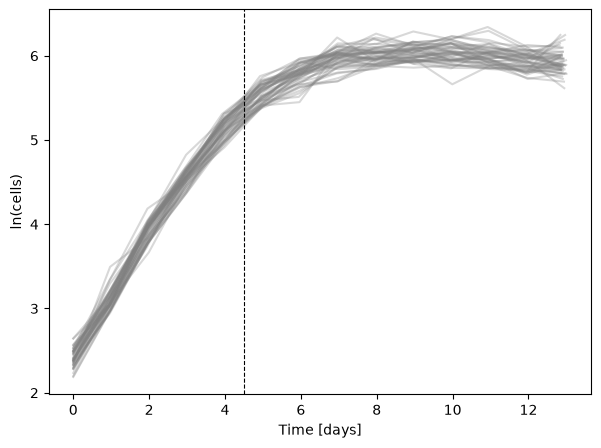

In [2]:
fig, ax = plt.subplots(figsize=(7, 5)) # new figure
for bid, d in train.groupby("batch_id"): # one line per batch
    ax.plot(d["elapsed_time"], np.log(d["cells"]), color="grey", alpha=0.3) # ln(cells) vs time
ax.axvline(4.5, color="black", linestyle="--", linewidth=0.8) # end of fitting window
ax.set_xlabel("Time [days]") # x label
ax.set_ylabel("ln(cells)") # y label
plt.show() # draw

**Per-batch fit:** slope = mu, R² = how straight the line is (1 = perfect exponential). One shared mu = mean over batches.

In [19]:
early = train[train["elapsed_time"] <= 4.5] # exponential phase
rows = [] # one result per batch
for bid, d in early.groupby("batch_id"): # loop over batches
    t, y = d["elapsed_time"].to_numpy(), np.log(d["cells"].to_numpy()) # time, ln(cells)
    slope, intercept = np.polyfit(t, y, 1) # straight-line fit
    r2 = 1 - np.sum((y - intercept - slope * t) ** 2) / np.sum((y - y.mean()) ** 2) # goodness of line fit
    rows.append({"batch_id": bid, "mu": slope, "r2": r2}) # store
fit_exp = pd.DataFrame(rows).set_index("batch_id") # results table
mu_mean = fit_exp["mu"].mean() # one shared mu
print(f"mu = {mu_mean:.3f} 1/day, doubling time = {np.log(2) / mu_mean * 24:.1f} h") # summary
#display(fit_exp.round(3)) # mu and R² for each batch
fit_exp.describe().round(3) # summary over batches

mu = 0.692 1/day, doubling time = 24.0 h


,mu,r2
count,49.000,49.000
mean,0.692,0.993
std,0.021,0.007
min,0.634,0.961
25%,0.681,0.992
50%,0.692,0.994
75%,0.705,0.997
max,0.757,0.999


## A.2 First simulation
**Idea:** instead of the formula, integrate dN/dt numerically (`solve_ivp`) from day 0: the same machinery will run the full model, whose equations have no closed-form solution. VCD = N / V.
**Expect:** good until day ~4, then overshoot → something slows growth.

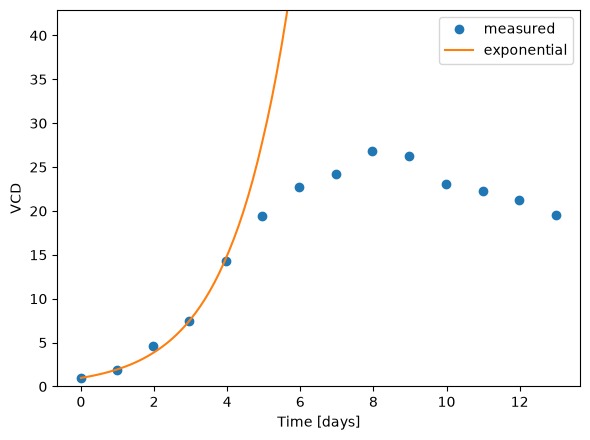

In [17]:
t_fine = np.linspace(0, pk["Batch1"]["t_pred"][-1], 200) # fine time grid
sim_exp = mech.simulate("exponential", pk["Batch1"], {"mu": mu_mean}, t_fine) # exponential model, Batch1
ev.plot_batch(d1, {"exponential": sim_exp}) # measured vs simulated

**Check on all batches (days 0–4.5):** each batch simulated from its own day 0 with the shared mu.
Table: mean relative error per day. Plot: predicted vs measured, diagonal = perfect.
**Expect:** errors below ~10 %, points on the diagonal → one mu describes the exponential phase of every batch.

elapsed_time,0.0,1.0,2.0,3.0,4.0
vcd,0.0,0.083,0.131,0.094,0.072


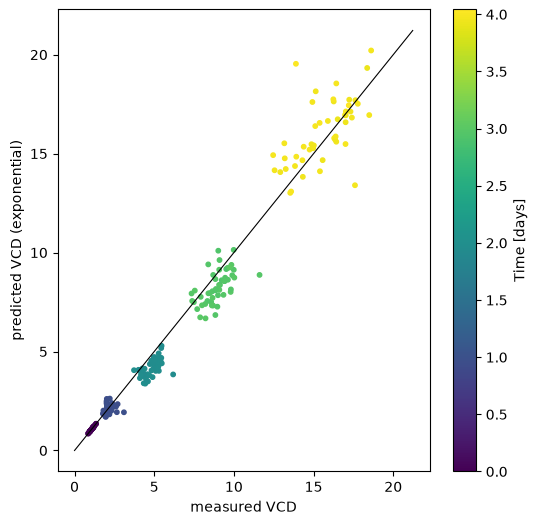

In [ ]:
pred_exp = mech.simulate_many("exponential", pk, {"mu": mu_mean}, with_day0=True) # all batches, all sample times
pred_exp_early = pred_exp[pred_exp["elapsed_time"] <= 4.5] # exponential phase only
display(ev.error_by_day(pred_exp_early, train, ["vcd"]).T.round(3)) # mean relative error per day
ev.parity_plot(pred_exp_early, train, "vcd", "exponential") # predicted vs measured

## A.3 What slows growth down?
**Idea:** compute the growth rate in every interval between two samples, then check which variable it follows.
mu_obs = [ln N(next) − ln N(now)] / Δt → slope piece by piece. > 0 growth, ≈ 0 plateau, < 0 net death.
**Read:** the candidate with the tightest, clearest trend is the brake. Correlation helps, but variables that change together over time look alike → pick the one with a plausible mechanism.

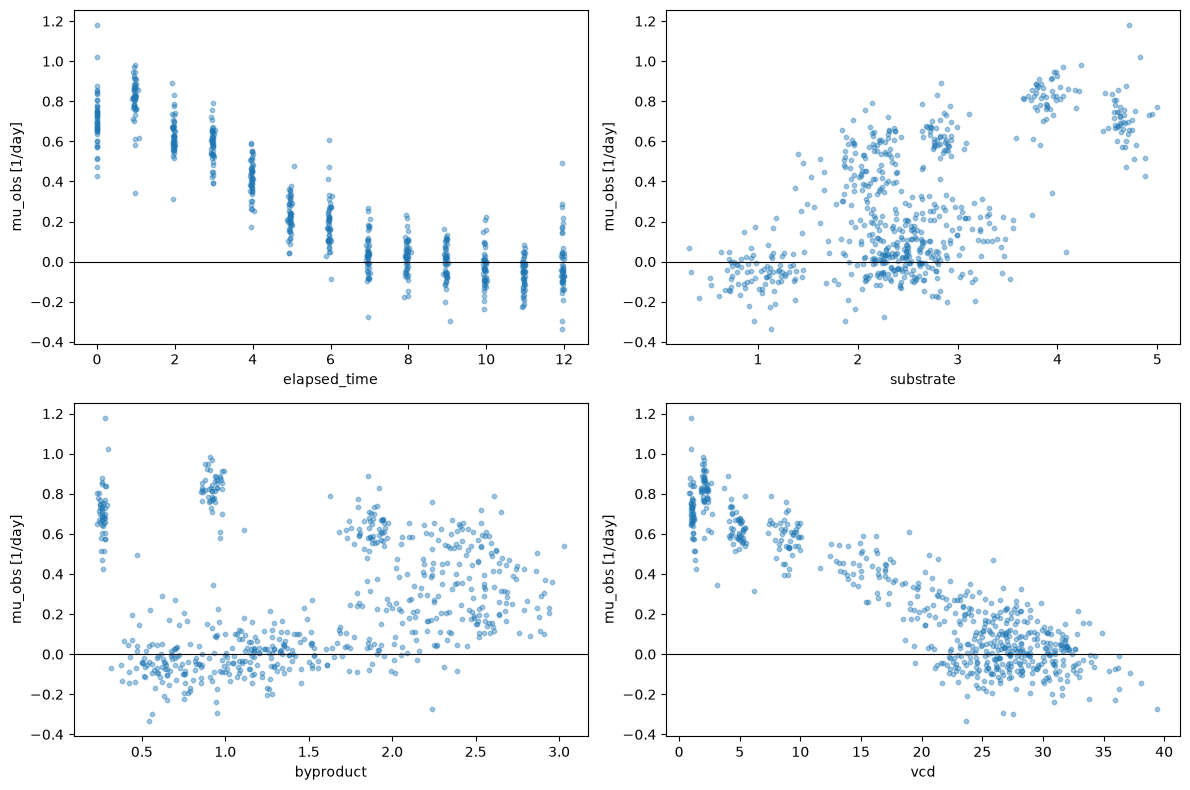

mu_obs          1.000
elapsed_time   -0.899
substrate       0.619
byproduct       0.085
vcd            -0.915
Name: mu_obs, dtype: float64

In [6]:
train["ln_cells"] = np.log(train["cells"]) # ln of total viable cells
dt_next = train.groupby("batch_id")["elapsed_time"].diff().shift(-1) # time to next sample (NaN at last sample)
train["mu_obs"] = train.groupby("batch_id")["ln_cells"].diff().shift(-1) / dt_next # growth rate to next sample

fig, axes = plt.subplots(2, 2, figsize=(12, 8)) # 2x2 grid of plots
for ax, col in zip(axes.flat, ["elapsed_time", "substrate", "byproduct", "vcd"]): # one candidate per plot
    ax.scatter(train[col], train["mu_obs"], s=10, alpha=0.4) # mu_obs vs candidate
    ax.axhline(0, color="black", linewidth=0.8) # zero-growth line
    ax.set_xlabel(col) # x label
    ax.set_ylabel("mu_obs [1/day]") # y label
plt.tight_layout() # avoid overlaps
plt.show() # draw
train[["mu_obs", "elapsed_time", "substrate", "byproduct", "vcd"]].corr()["mu_obs"].round(3) # correlation with mu_obs

**Result:** VCD gives the tightest trend (r ≈ −0.91). Substrate stays 2–3 g/L while growth stops → not the brake (its r ≈ 0.6 only follows time). Byproduct: no link.

## A.4 Logistic growth (density brake)
**Model:** mu = mu_max · (1 − VCD / VCD_max). Contains the exponential: VCD ≪ VCD_max → mu ≈ mu_max.
**Estimate:** mu_obs vs VCD is a line → intercept = mu_max, zero crossing = VCD_max.
Growth phase only (days < 6.5): later, mu_obs also contains death (modelled in A.5).

{'mu_max': 0.78, 'vcd_max': 33.925}


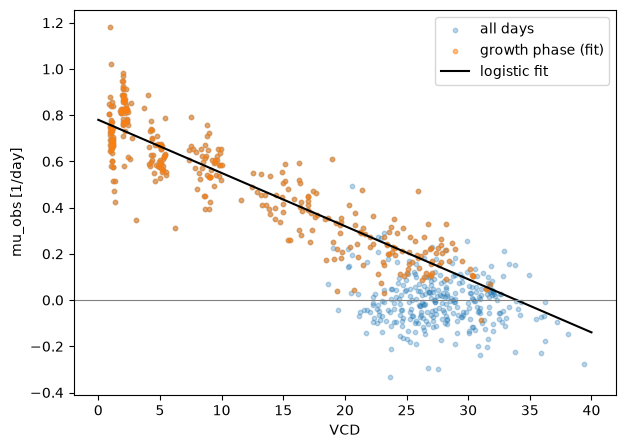

In [20]:
growth = train[train["elapsed_time"] < 6.5].dropna(subset=["mu_obs"]) # growth phase, valid rates
slope, intercept = np.polyfit(growth["vcd"], growth["mu_obs"], 1) # line mu_obs vs vcd
p_log = {"mu_max": float(intercept), "vcd_max": float(-intercept / slope)} # logistic parameters
print({k: round(v, 3) for k, v in p_log.items()}) # show parameters

fig, ax = plt.subplots(figsize=(7, 5)) # new figure
ax.scatter(train["vcd"], train["mu_obs"], s=10, alpha=0.3, label="all days") # all points
ax.scatter(growth["vcd"], growth["mu_obs"], s=10, alpha=0.5, label="growth phase (fit)") # fitted points
v = np.linspace(0, 40, 100) # density grid
ax.plot(v, p_log["mu_max"] * (1 - v / p_log["vcd_max"]), color="black", label="logistic fit") # fitted line
ax.axhline(0, color="grey", linewidth=0.8) # zero-growth line
ax.set_xlabel("VCD") # x label
ax.set_ylabel("mu_obs [1/day]") # y label
ax.legend() # legend
plt.show() # draw

**Sensitivity:** does the growth-phase cutoff change the parameters? Small changes = robust estimate.

In [8]:
for cut in [5.5, 6.5, 7.5]: # different growth-phase cutoffs
    gr = train[train["elapsed_time"] < cut].dropna(subset=["mu_obs"]) # rows before cutoff
    s, i = np.polyfit(gr["vcd"], gr["mu_obs"], 1) # line fit
    print(f"cutoff {cut}: mu_max = {i:.3f}, vcd_max = {-i / s:.1f}") # parameters

cutoff 5.5: mu_max = 0.787, vcd_max = 32.5
cutoff 6.5: mu_max = 0.780, vcd_max = 33.9
cutoff 7.5: mu_max = 0.783, vcd_max = 33.2


**Simulation:** Batch1 (exponential vs logistic), then all 49 batches from their own day 0, as for the test batches.
**Expect:** peak captured; days 10–13 too high (no death); horizontal bands in the parity plot = same curve for every batch.

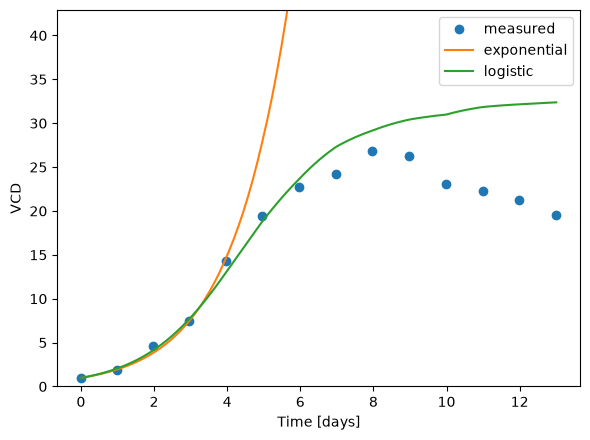

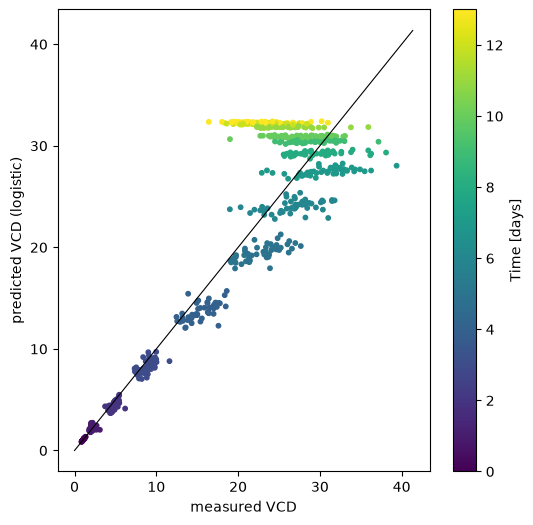

elapsed_time,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0,13.0
vcd,0.0,0.092,0.083,0.085,0.122,0.131,0.117,0.117,0.075,0.083,0.155,0.251,0.388,0.462


In [9]:
sim_log = mech.simulate("logistic", pk["Batch1"], p_log, t_fine) # logistic model, Batch1
ev.plot_batch(d1, {"exponential": sim_exp, "logistic": sim_log}) # measured vs simulated

pred_log = mech.simulate_many("logistic", pk, p_log, with_day0=True) # all batches
err_log = ev.error_by_day(pred_log, train, ["vcd"]) # mean relative error per day
ev.parity_plot(pred_log, train, "vcd", "logistic") # predicted vs measured
err_log.T.round(3) # error per day

## A.5 Cell death and cumulative brake
### A.5.1 Observed death rate
Dead cells stay in the reactor: D = (TCD − VCD)·V. They increase only because viable cells die: dD/dt = kd·N.
Per interval: kd_obs = ΔD / (mean N · Δt). Assumption: no lysis (dead cells do not dissolve).

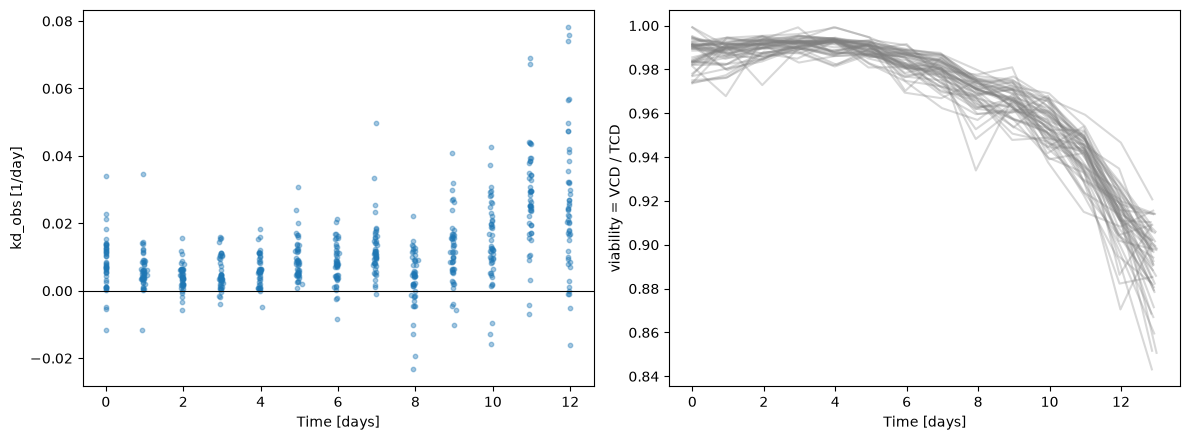

elapsed_time,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0,13.0
mu_obs,0.7102,0.8126,0.6317,0.5823,0.4182,0.2324,0.1904,0.0375,0.0260,-0.0050,-0.0260,-0.0657,-0.0112,NaN
kd_obs,0.0083,0.0062,0.0041,0.0052,0.0062,0.0091,0.0081,0.0123,0.0036,0.0119,0.0143,0.0274,0.0253,NaN


In [21]:
train["dead"] = (train["tcd"] - train["vcd"]) * train["volume"] # total dead cells
cells_mean = 0.5 * (train["cells"] + train.groupby("batch_id")["cells"].shift(-1)) # mean viable cells in interval
train["kd_obs"] = train.groupby("batch_id")["dead"].diff().shift(-1) / (cells_mean * dt_next) # death rate to next sample

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5)) # two plots side by side
axes[0].scatter(train["elapsed_time"], train["kd_obs"], s=10, alpha=0.4) # death rate vs time
axes[0].axhline(0, color="black", linewidth=0.8) # zero line
axes[0].set_xlabel("Time [days]") # x label
axes[0].set_ylabel("kd_obs [1/day]") # y label
for bid, d in train.groupby("batch_id"): # one line per batch
    axes[1].plot(d["elapsed_time"], d["vcd"] / d["tcd"], color="grey", alpha=0.3) # viability
axes[1].set_xlabel("Time [days]") # x label
axes[1].set_ylabel("viability = VCD / TCD") # y label
plt.tight_layout() # avoid overlaps
plt.show() # draw
train.groupby(train["elapsed_time"].round())[["mu_obs", "kd_obs"]].mean().round(4).T # mean rates per day

**Result:** death is small (~0.5–1 %/day, ~2.5 %/day at the end). From day 7 to 13 VCD drops ~27 % but total viable cells only ~4 %: the decline after the peak is mostly **dilution**. Cells stop dividing even when diluted → the logistic model wrongly restarts growth.

### A.5.2 A cumulative brake?
IVCD = ∫VCD dt (area under the VCD curve): cumulative cell load, never decreases, not reset by dilution → proxy for unmeasured nutrients used up / waste accumulated.
Gross growth mu_g = mu_obs + kd_obs (births only) → all days usable, no cutoff.
Compare two linear models for mu_g: density only vs density + IVCD (lower RMSE = better).

In [22]:
dt_prev = train.groupby("batch_id")["elapsed_time"].diff() # time since previous sample
vcd_mid = 0.5 * (train["vcd"] + train.groupby("batch_id")["vcd"].shift(1)) # mean VCD in previous interval
train["ivcd"] = (vcd_mid * dt_prev).fillna(0).groupby(train["batch_id"]).cumsum() # running integral, 0 at day 0
train["mu_g"] = train["mu_obs"] + train["kd_obs"] # gross growth rate

fit = train.dropna(subset=["mu_g"]) # rows with valid rates
coefs = {} # coefficients per model
for name, cols in {"density": ["vcd"], "density + ivcd": ["vcd", "ivcd"]}.items(): # two candidate brakes
    A = np.c_[np.ones(len(fit)), fit[cols].to_numpy()] # design matrix: constant + variables
    coefs[name] = np.linalg.lstsq(A, fit["mu_g"].to_numpy(), rcond=None)[0] # least-squares coefficients
    rmse = np.sqrt(np.mean((A @ coefs[name] - fit["mu_g"].to_numpy()) ** 2)) # fit error
    print(f"{name}: coef = {coefs[name].round(4)}, rmse = {rmse:.4f}") # results

density: coef = [ 0.7935 -0.0268], rmse = 0.1272
density + ivcd: coef = [ 0.7728 -0.0196 -0.0013], rmse = 0.1049


**Plot:** left, gross growth vs VCD (late days below the density line). Right, what density alone misses vs IVCD (negative for large IVCD = cumulative brake).

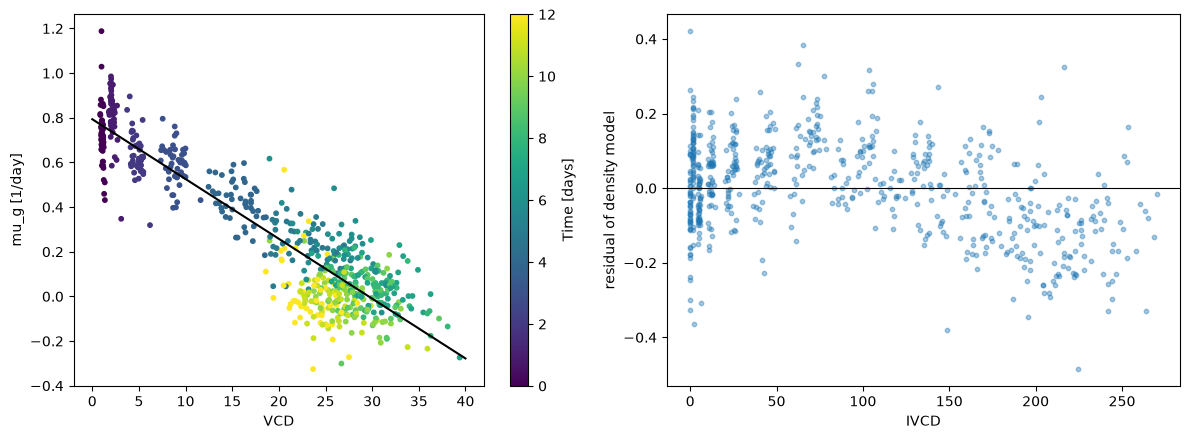

In [24]:
c0, c1 = coefs["density"] # density-only model
resid = fit["mu_g"] - (c0 + c1 * fit["vcd"]) # what density alone misses

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5)) # two plots side by side
sc = axes[0].scatter(fit["vcd"], fit["mu_g"], c=fit["elapsed_time"], s=10) # gross growth vs density
axes[0].plot(v, c0 + c1 * v, color="black") # density-only line
fig.colorbar(sc, ax=axes[0], label="Time [days]") # color legend
axes[0].set_xlabel("VCD") # x label
axes[0].set_ylabel("mu_g [1/day]") # y label
axes[1].scatter(fit["ivcd"], resid, s=10, alpha=0.4) # residual vs IVCD
axes[1].axhline(0, color="black", linewidth=0.8) # zero line
axes[1].set_xlabel("IVCD") # x label
axes[1].set_ylabel("residual of density model") # y label
plt.tight_layout() # avoid overlaps
plt.show() # draw

**Combined model (density + IVCD):**
- left: mu_g vs VCD, with model lines at fixed IVCD (0, 100, 200)
- middle: mu_g vs IVCD, with model lines at fixed VCD (5, 15, 25)
- right: predicted vs observed mu_g (diagonal = perfect)

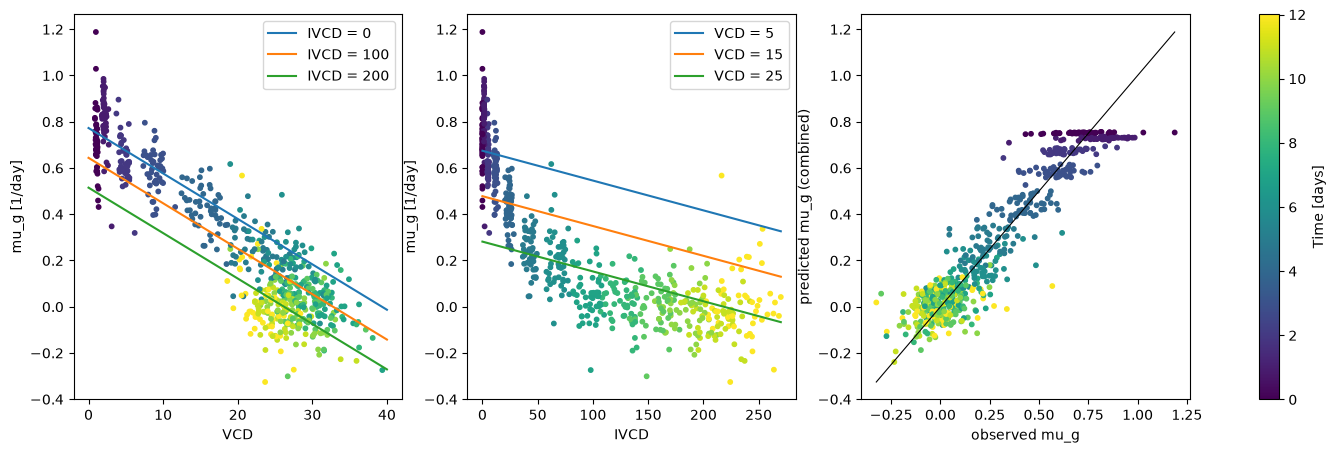

In [28]:
cb = coefs["density + ivcd"] # combined coefficients c0, c1, c2
mu_pred = cb[0] + cb[1] * fit["vcd"] + cb[2] * fit["ivcd"] # combined-model gross growth
vv = np.linspace(0, 40, 100) # VCD grid
iv = np.linspace(0, fit["ivcd"].max(), 100) # IVCD grid

fig, axes = plt.subplots(1, 3, figsize=(18, 5)) # three plots side by side
sc = axes[0].scatter(fit["vcd"], fit["mu_g"], c=fit["elapsed_time"], s=10) # mu_g vs VCD
for i0 in [0, 100, 200]: # fixed IVCD levels
    axes[0].plot(vv, cb[0] + cb[1] * vv + cb[2] * i0, label=f"IVCD = {i0}") # model line
axes[0].set_xlabel("VCD") # x label
axes[0].set_ylabel("mu_g [1/day]") # y label
axes[0].legend() # legend

axes[1].scatter(fit["ivcd"], fit["mu_g"], c=fit["elapsed_time"], s=10) # mu_g vs IVCD
for v0 in [5, 15, 25]: # fixed VCD levels
    axes[1].plot(iv, cb[0] + cb[1] * v0 + cb[2] * iv, label=f"VCD = {v0}") # model line
axes[1].set_xlabel("IVCD") # x label
axes[1].set_ylabel("mu_g [1/day]") # y label
axes[1].legend() # legend

axes[2].scatter(fit["mu_g"], mu_pred, c=fit["elapsed_time"], s=10) # predicted vs observed
lim = [fit["mu_g"].min(), fit["mu_g"].max()] # axis range
axes[2].plot(lim, lim, color="black", linewidth=0.8) # perfect-prediction line
axes[2].set_xlabel("observed mu_g") # x label
axes[2].set_ylabel("predicted mu_g (combined)") # y label
fig.colorbar(sc, ax=axes, label="Time [days]") # shared color legend
plt.show() # draw

### A.5.3 Full cell model
States: viable N, dead D, IVCD.
- dN/dt = (mu − kd)·N, dD/dt = kd·N, dIVCD/dt = N/V
- mu = mu_max·(1 − VCD/VCD_max − IVCD/IVCD_max)
- kd = kd0 + kd1·IVCD (death rises with cumulative load)

Starting parameters: growth from A.5.2, death from a line kd_obs vs IVCD.

In [29]:
kfit = train.dropna(subset=["kd_obs"]) # rows with valid death rate
A = np.c_[np.ones(len(kfit)), kfit["ivcd"].to_numpy()] # design matrix: constant + IVCD
kd0, kd1 = np.linalg.lstsq(A, kfit["kd_obs"].to_numpy(), rcond=None)[0] # least-squares fit
c0, c1, c2 = coefs["density + ivcd"] # growth coefficients
p = {"mu_max": c0, "vcd_max": -c0 / c1, "ivcd_max": -c0 / c2, "kd0": kd0, "kd1": kd1} # cell-model parameters
{k: round(float(val), 5) for k, val in p.items()} # show parameters

{'mu_max': 0.77284,
 'vcd_max': 39.33649,
 'ivcd_max': 599.34319,
 'kd0': 0.00445,
 'kd1': 7e-05}

**Simulation:** Batch1 (VCD, TCD), then all batches. Error per day compared with A.4.
**Expect:** decline after the peak now present; big gain on days 10–13.

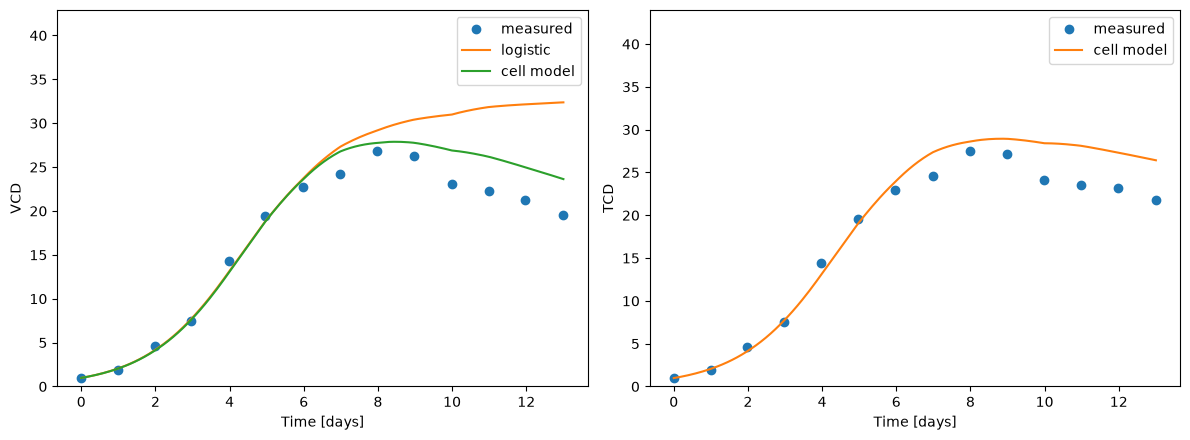

,A.4 vcd,A.5 vcd,A.5 tcd
elapsed_time,,,
0.0,0.000,0.000,0.000
1.0,0.092,0.089,0.089
2.0,0.083,0.091,0.092
3.0,0.085,0.092,0.092
4.0,0.122,0.126,0.126
5.0,0.131,0.132,0.131
6.0,0.117,0.120,0.121
7.0,0.117,0.133,0.132
8.0,0.075,0.086,0.087


In [30]:
sim_cells = mech.simulate("cells", pk["Batch1"], p, t_fine) # cell model, Batch1
ev.plot_batch(d1, {"logistic": sim_log, "cell model": sim_cells}, cols=("vcd", "tcd")) # measured vs simulated

pred_cells = mech.simulate_many("cells", pk, p, with_day0=True) # all batches
err_cells = ev.error_by_day(pred_cells, train, ["vcd", "tcd"]) # mean relative error per day
comparison = pd.DataFrame({"A.4 vcd": err_log["vcd"], "A.5 vcd": err_cells["vcd"], "A.5 tcd": err_cells["tcd"]}) # side by side
comparison.loc["mean 1–13"] = comparison.loc[comparison.index > 0].mean() # overall mean
comparison.round(3) # error table

### A.5.4 Joint fit
Parameters above come from noisy day-by-day rates, each estimated separately. Now all 5 are fitted **together on the full VCD and TCD curves** of the 49 batches: `least_squares` minimizes the sum of squared relative errors.
- parameters in log scale → always positive, comparable magnitudes
- `diff_step=1e-3` → finite-difference step larger than the integrator noise
- takes ~10 s

In [31]:
p_fit = mech.fit_cells(pk, p) # joint fit, start from A.5.3 values
for label, q in {"A.5.3": p, "joint fit": p_fit}.items(): # two parameter sets
    err = np.abs(mech.residuals_cells(np.log([q[k] for k in mech.CELL_PARAMS]), pk)).mean() # mean relative error
    print(f"{label}: error = {err:.4f}, params = { {k: round(float(val), 5) for k, val in q.items()} }") # results

A.5.3: error = 0.1034, params = {'mu_max': 0.77284, 'vcd_max': 39.33649, 'ivcd_max': 599.34319, 'kd0': 0.00445, 'kd1': 7e-05}
joint fit: error = 0.0817, params = {'mu_max': 0.79993, 'vcd_max': 45.39647, 'ivcd_max': 436.47135, 'kd0': 0.00461, 'kd1': 6e-05}


### A.5.5 Team benchmark
Hold-out: Batch2, 3, 11, 18, 19, 20, 23, 28, 39, 42; train on the other 39. Each test batch starts from its first measurement.
Score = normalized RMSE: errors / target std → squared → mean per batch and target → √(mean of the 40 batch–target values). Lower is better.
Cell model refitted on the 39 training batches only (no peeking at the test). Substrate and byproduct: mean curve as placeholder until A.6–A.7.

In [32]:
bench_train, bench_test = ev.split_benchmark(meas) # 39 train / 10 test batches
sd = ev.target_sd(bench_train) # normalization per target
base = ev.baseline_mean(bench_train, bench_test) # mean-curve predictions

pk_bench = {bid: pk[bid] for bid in bench_train["batch_id"].unique()} # train packages
pk_test = {bid: pk[bid] for bid in ev.TEST_BATCHES} # test packages
p_bench = mech.fit_cells(pk_bench, p) # fit on 39 batches only
pred_bench = mech.simulate_many("cells", pk_test, p_bench) # VCD, TCD on test batches
pred_bench = pred_bench.merge(base[["batch_id", "elapsed_time", "substrate", "byproduct"]], on=["batch_id", "elapsed_time"]) # placeholder metabolites

scores = {} # per-target scores per model
for label, pr in {"baseline": base, "cell model A.5": pred_bench}.items(): # two models
    total, per_target = ev.team_score(pr, bench_test, sd) # evaluate
    scores[label] = {**per_target.to_dict(), "score": total} # store
pd.DataFrame(scores).T.round(3) # benchmark table

,vcd,tcd,substrate,byproduct,score
baseline,0.260,0.256,0.414,0.247,0.302
cell model A.5,0.258,0.252,0.414,0.247,0.301


**Result:** cell model ≈ baseline on VCD/TCD; substrate is the worst target (~0.41) and depends directly on the feeds → next step **A.6: substrate mass balance with feeds**.

## A.6 Metabolites: substrate and byproduct
Tested mass balances with feed additions (feed B and feed substrate carry substrate, consumption per cell from growth/maintenance/substrate level, byproduct produced with growth and consumed later): none beat the mean curve on the benchmark (substrate 0.73 vs 0.41, byproduct 0.66–0.85 vs 0.25). Errors accumulate over time and the operator keeps substrate in a narrow range (2–3 g/L).
**Insight:** in days 0–4 the byproduct increases by almost exactly the amount of substrate consumed → overflow metabolism (substrate converted ~1:1 into byproduct), at a rate per litre rather than per cell.
**Decision:** final Plan A = mechanistic cell model for VCD/TCD + mean curve for substrate/byproduct.

,substrate consumed,byproduct produced
elapsed_time,,
0.0,0.77,0.66
1.0,1.06,0.93
2.0,0.65,0.47
3.0,0.18,0.16
4.0,-0.37,-0.06
5.0,-0.68,-0.09


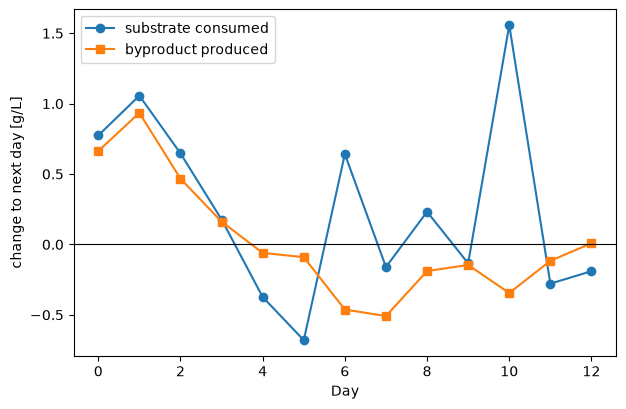

In [33]:
daily = train.groupby(train["elapsed_time"].round())[["substrate", "byproduct"]].mean() # mean concentrations per day
flux = pd.DataFrame({"substrate consumed": -daily["substrate"].diff(), "byproduct produced": daily["byproduct"].diff()}).shift(-1) # change to next day
display(flux.loc[0:5].round(2)) # days 0–5

fig, ax = plt.subplots(figsize=(7, 4.5)) # new figure
ax.plot(flux.index, flux["substrate consumed"], "o-", label="substrate consumed") # substrate decrease per day
ax.plot(flux.index, flux["byproduct produced"], "s-", label="byproduct produced") # byproduct increase per day
ax.axhline(0, color="black", linewidth=0.8) # zero line
ax.set_xlabel("Day") # x label
ax.set_ylabel("change to next day [g/L]") # y label
ax.legend() # legend
plt.show() # draw

## A.7 Plan A summary
| | VCD | TCD | substrate | byproduct | score |
|---|---|---|---|---|---|
| baseline (mean curve) | 0.260 | 0.256 | 0.414 | 0.247 | 0.302 |
| Plan A | 0.258 | 0.252 | 0.414 | 0.247 | 0.301 |

Key messages:
- growth is limited by cell density and cumulative cell load (IVCD), not by substrate
- after the peak VCD declines mostly by dilution; cells stop dividing and die slowly (~0.5 → 2 %/day)
- early metabolism is overflow: substrate is converted ~1:1 into byproduct
- batches start almost identical, so any model starting from day 0 predicts curves close to the mean